In [15]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt

data = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [36]:
!curl -o data.csv $data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  954k  100  954k    0     0  1749k      0 --:--:-- --:--:-- --:--:-- 1748k


In [5]:
df = pd.read_csv('data.csv')

In [6]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

string_columns = list(df.dtypes[df.dtypes == 'string'].index)
for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')
    df[col] = df[col].str.lower().str.replace('-', '_')

df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce')
df['totalcharges'] = df['totalcharges'].fillna(0)

df['churn'] = (df['churn'] == 'yes').astype(int)

In [7]:
categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice',
    'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup',
    'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies',
    'contract', 'paperlessbilling', 'paymentmethod'
]
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['churn'].values
y_val = df_val['churn'].values
y_test = df_test['churn'].values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [9]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

y_pred_proba = model.predict_proba(X_val_scaled)[:, 1]
churn_decision = (y_pred_proba >= 0.5).astype(int)

(y_val == churn_decision).mean()

np.float64(0.8041163946061036)

## Accuracy and dummy model

In [13]:
total = len(y_val)
correct = (y_val == churn_decision).sum()

accuracy = correct/total
accuracy

np.float64(0.8041163946061036)

In [19]:
thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    churn_decision = (y_pred_proba >= t)
    score = (y_val == churn_decision).mean()
    print('%.2f %.3f' %(t, score))
    scores.append(score)

0.00 0.274
0.05 0.513
0.10 0.605
0.15 0.661
0.20 0.703
0.25 0.736
0.30 0.757
0.35 0.764
0.40 0.781
0.45 0.792
0.50 0.804
0.55 0.803
0.60 0.797
0.65 0.789
0.70 0.765
0.75 0.742
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


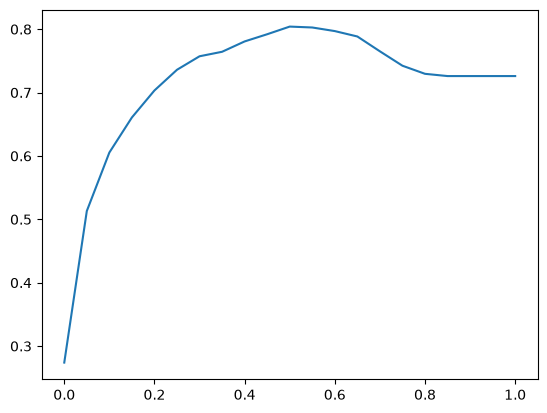

In [20]:
plt.plot(thresholds, scores)

0.5 threshold has best accuracy

In [21]:
from sklearn.metrics import accuracy_score

In [ ]:
thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred_proba >= t)    # Scikit-learn has method for calculating accuracy.
    print('%.2f %.3f' %(t, score))
    scores.append(score)

0.00 0.274
0.05 0.513
0.10 0.605
0.15 0.661
0.20 0.703
0.25 0.736
0.30 0.757
0.35 0.764
0.40 0.781
0.45 0.792
0.50 0.804
0.55 0.803
0.60 0.797
0.65 0.789
0.70 0.765
0.75 0.742
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


⭐️
Here setting t=1.0 is called dummy/baseline model. Our prediction will never output 1.0 probability, so it override the model and predict only False (no one churn) and it still give 73% accuracy. => So why do we need a model with so much complexity and work, if simple dummy model is giving a decent accuracy?

While 73% accuracy sounds decent on paper, the dummy model provides $0 business value because it fails 100% of the time at the actual goal.

That is basic thing for model, we always dont want false, so we use ml model, so what is base of the video? what are the problems identified then?

Accuracy is a broken metric for imbalanced classification problems
The "Majority Class Trap" occurs when a model achieves artificially high accuracy simply by predicting the most common outcome every time, while completely failing to identify the rare events you actually care about.
We have 73% no churn and 27% churn people in our dataset.

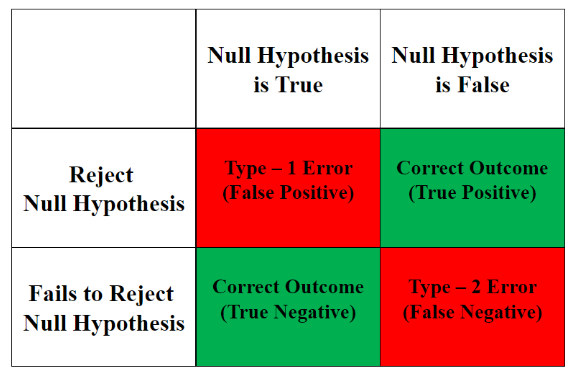{width=300px} 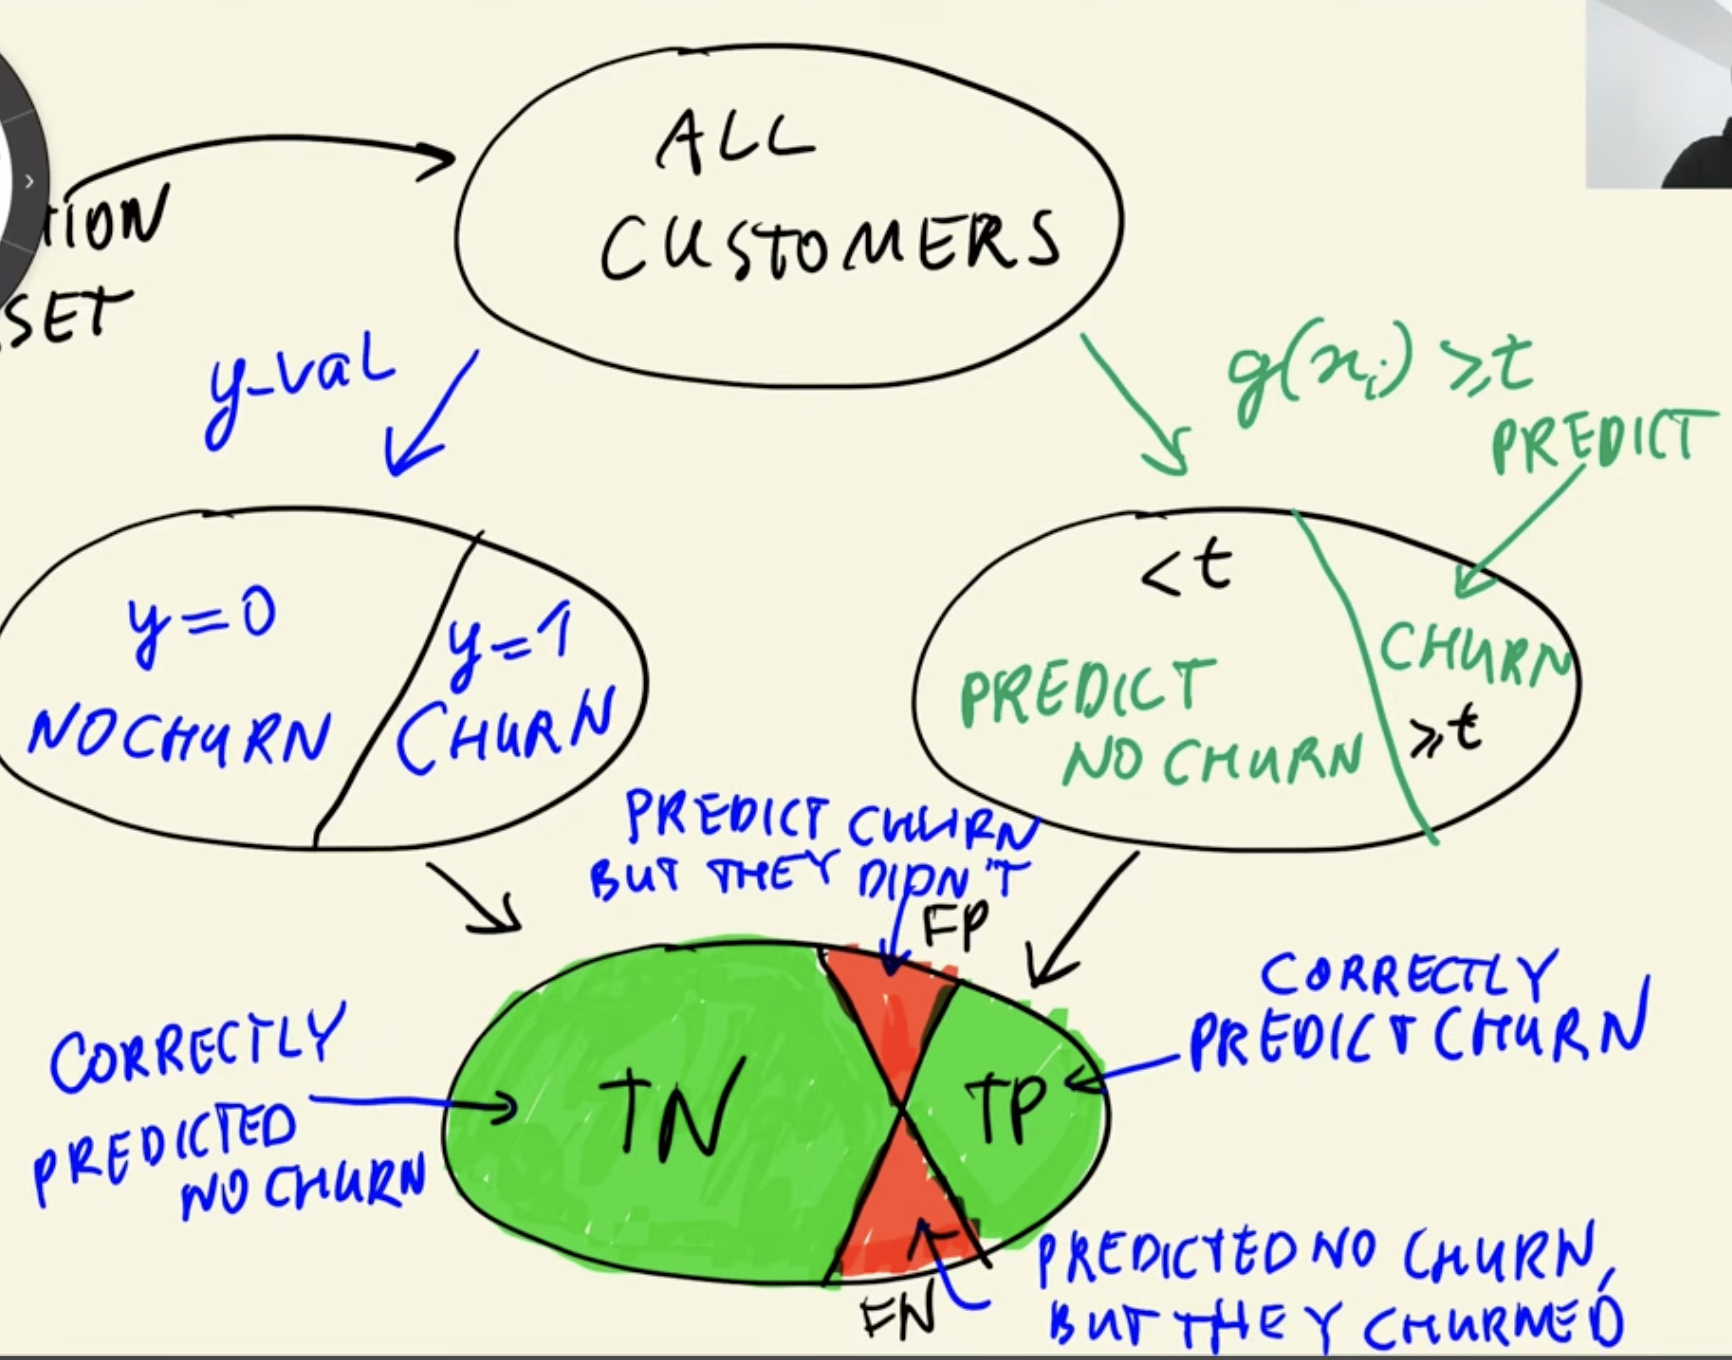{width=300px} 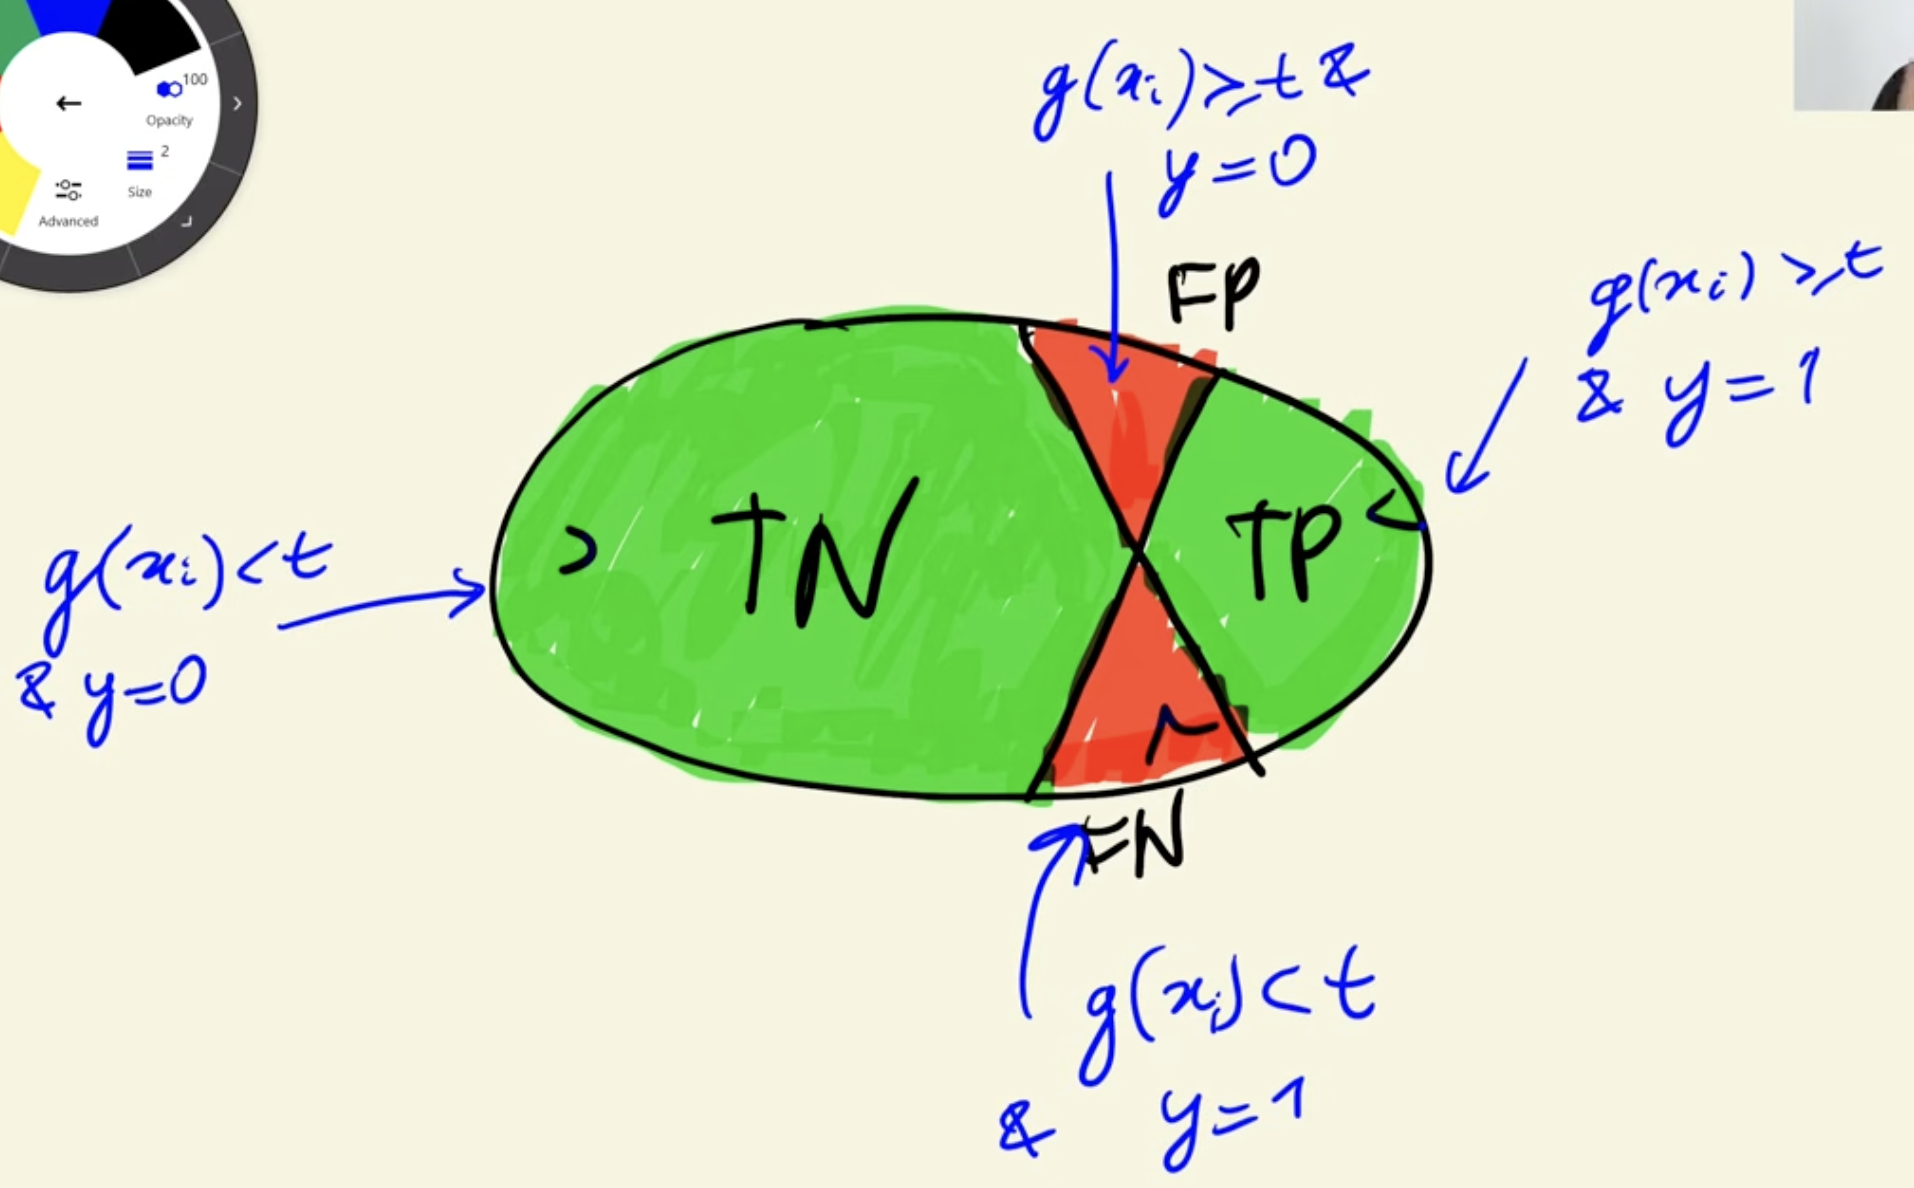{width=300px} 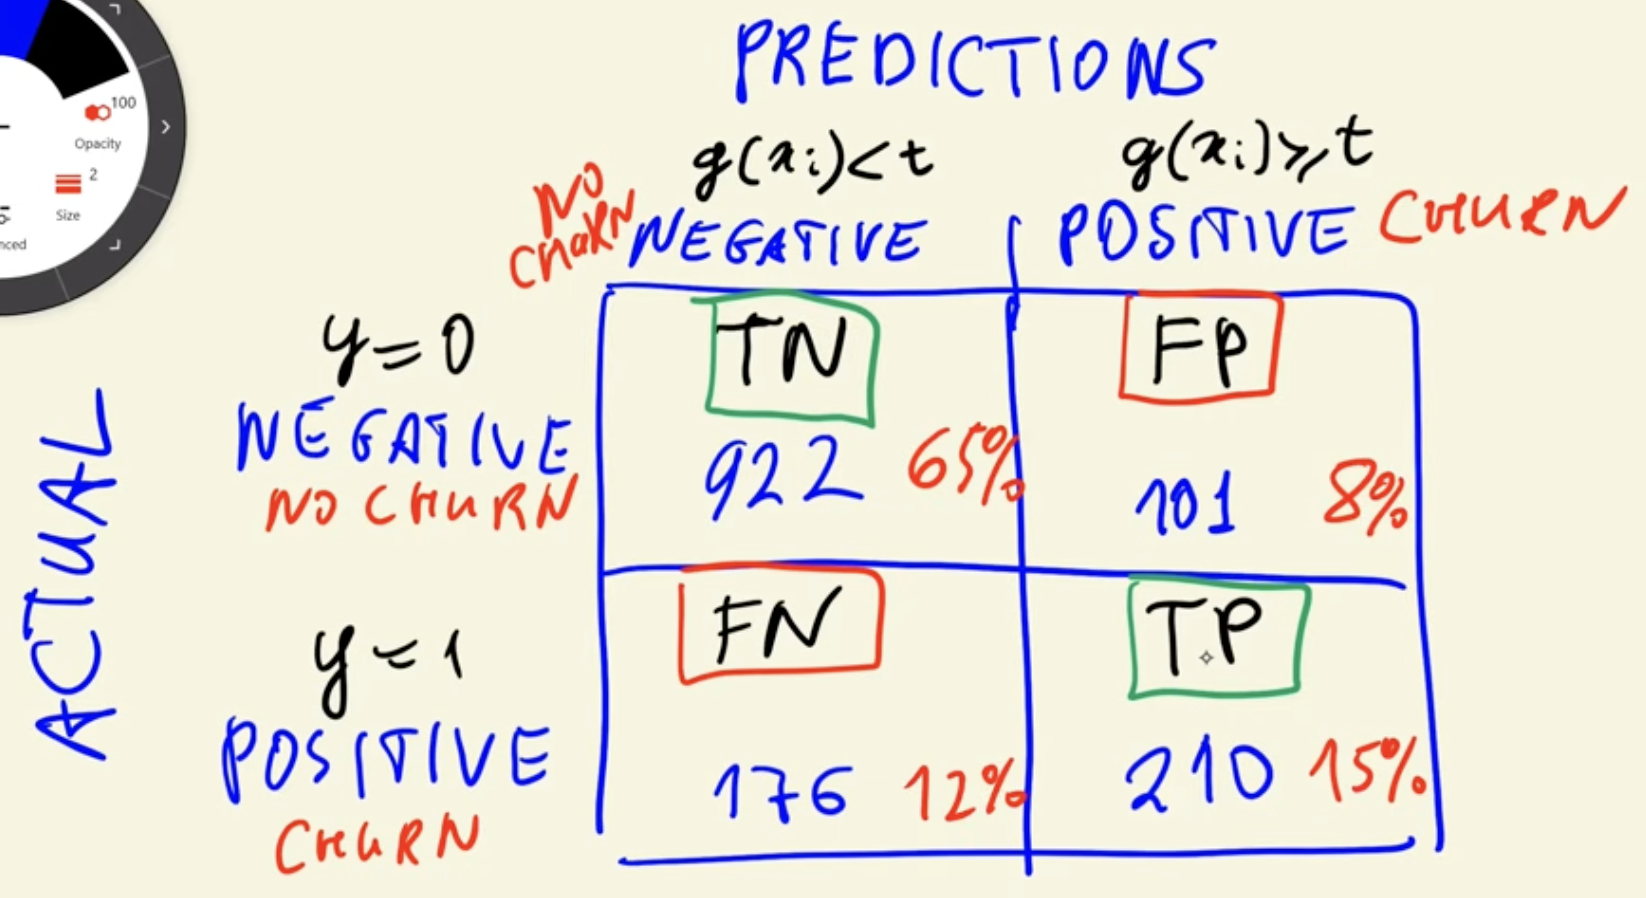{width=300px}

## Confusion table

In [23]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred_proba >= t)
predict_negative = (y_pred_proba < t)

In [24]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [28]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

confusion_matrix

array([[921, 102],
       [174, 212]])

## Precision and Recall

**Precision**: Fraction of Positive prediction that are correct. (TP - FP)
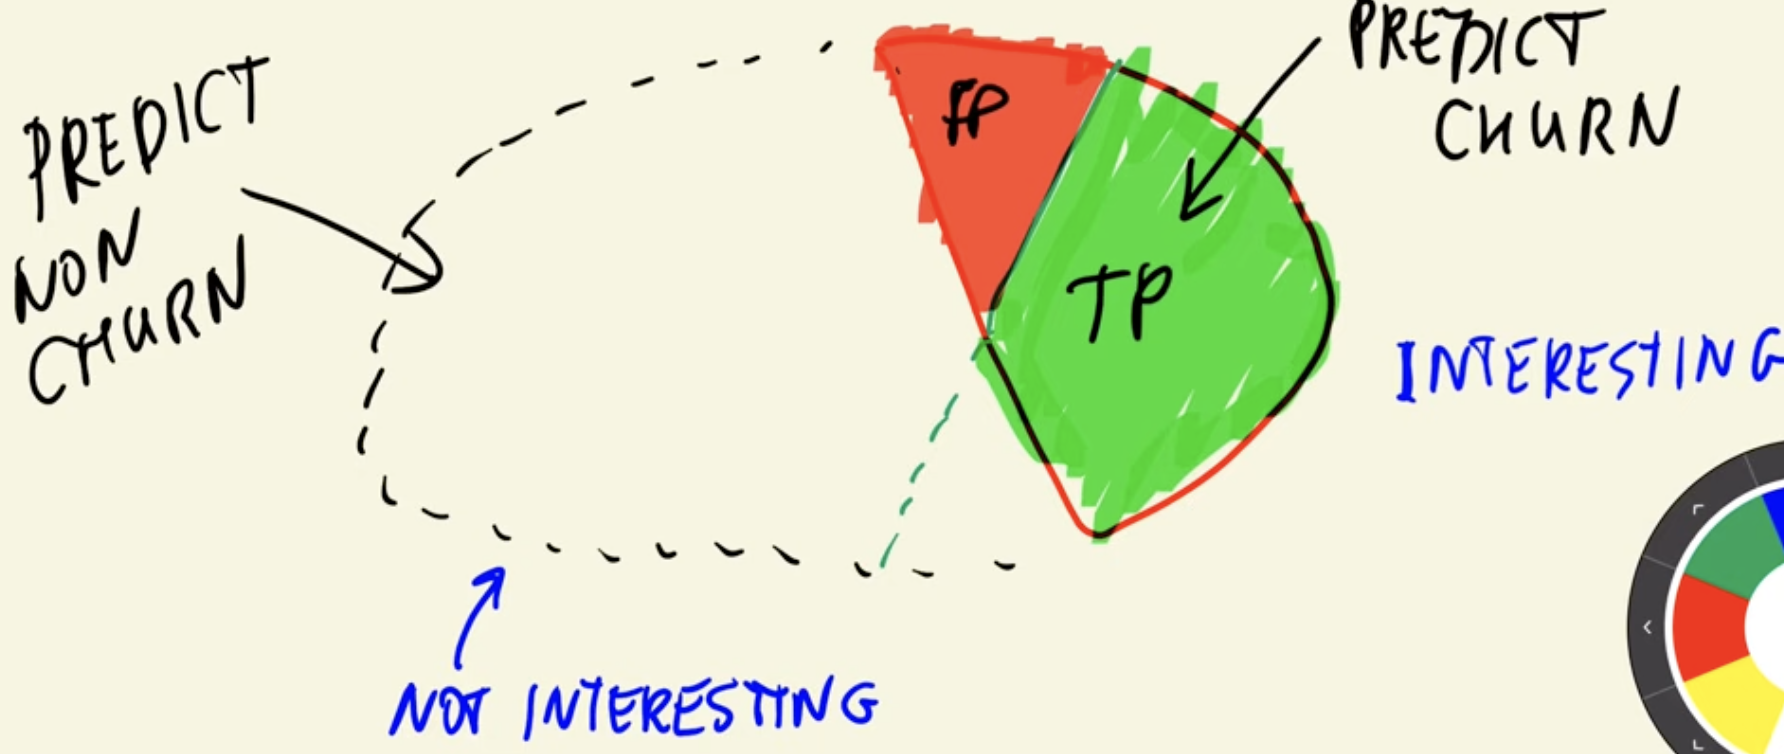{width=300px}
<br>
**Recall**: Fraction of correctly identified positive examples. (y=1 - FN) 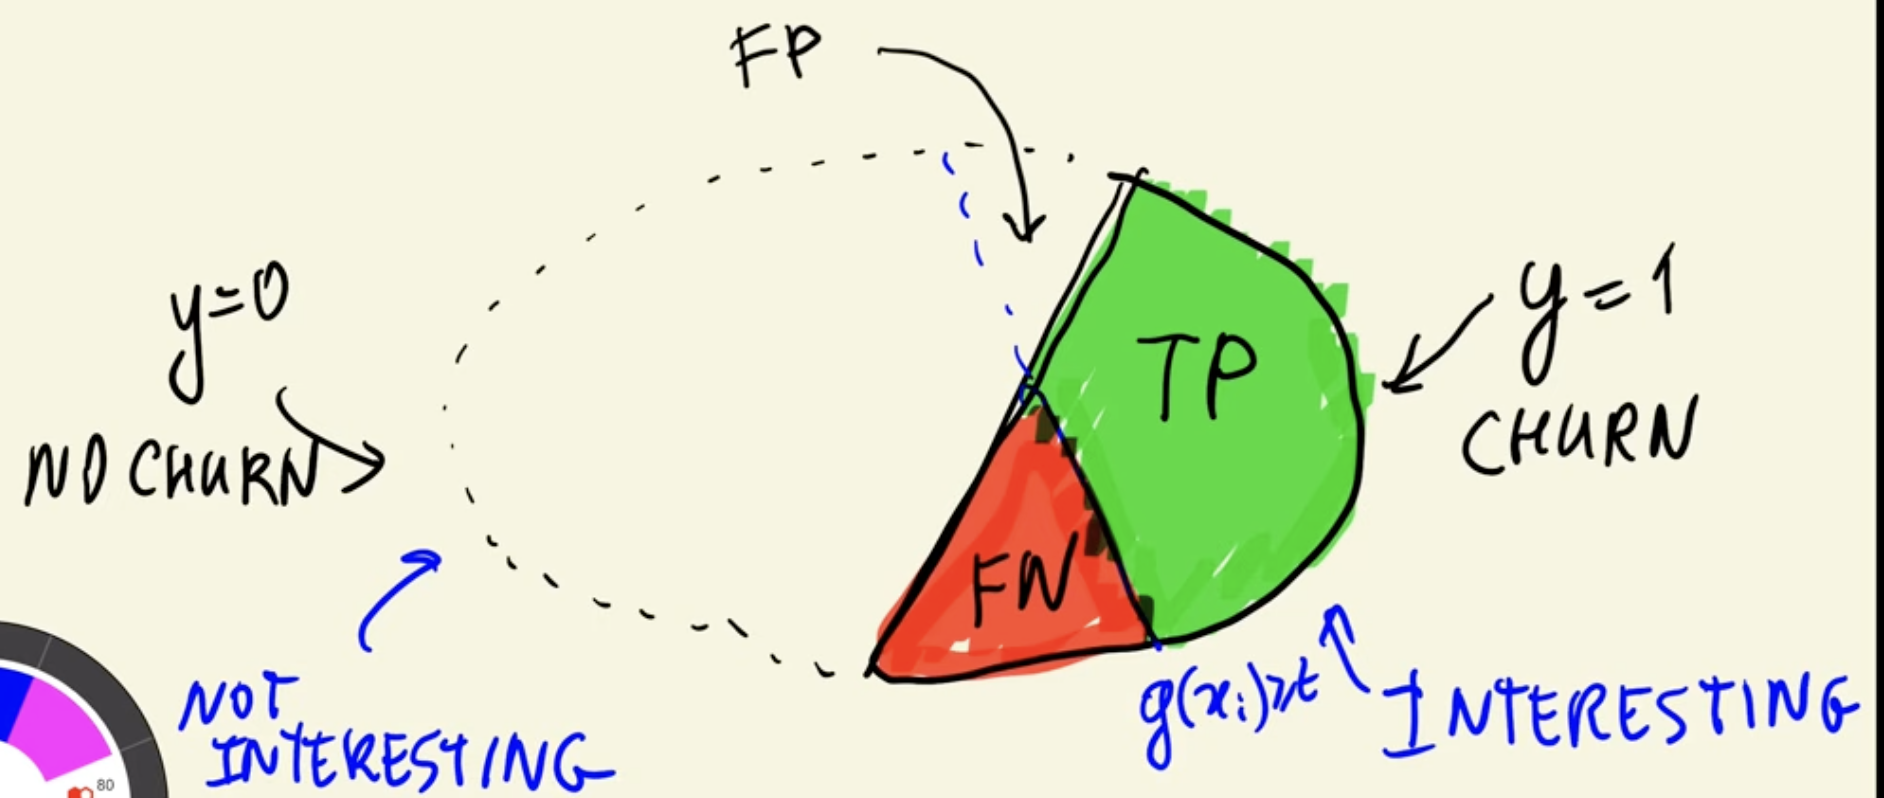{width=300px}

In [30]:
precision = tp / (tp+fp)
precision

np.float64(0.6751592356687898)

In [31]:
recall = tp / (tp+fn)
recall

np.float64(0.5492227979274611)

In [32]:
accuracy

np.float64(0.8041163946061036)

Therefore in case like these (class imbalance), accuracy can be misleading.

## ROC Curves

### TPR and FRP
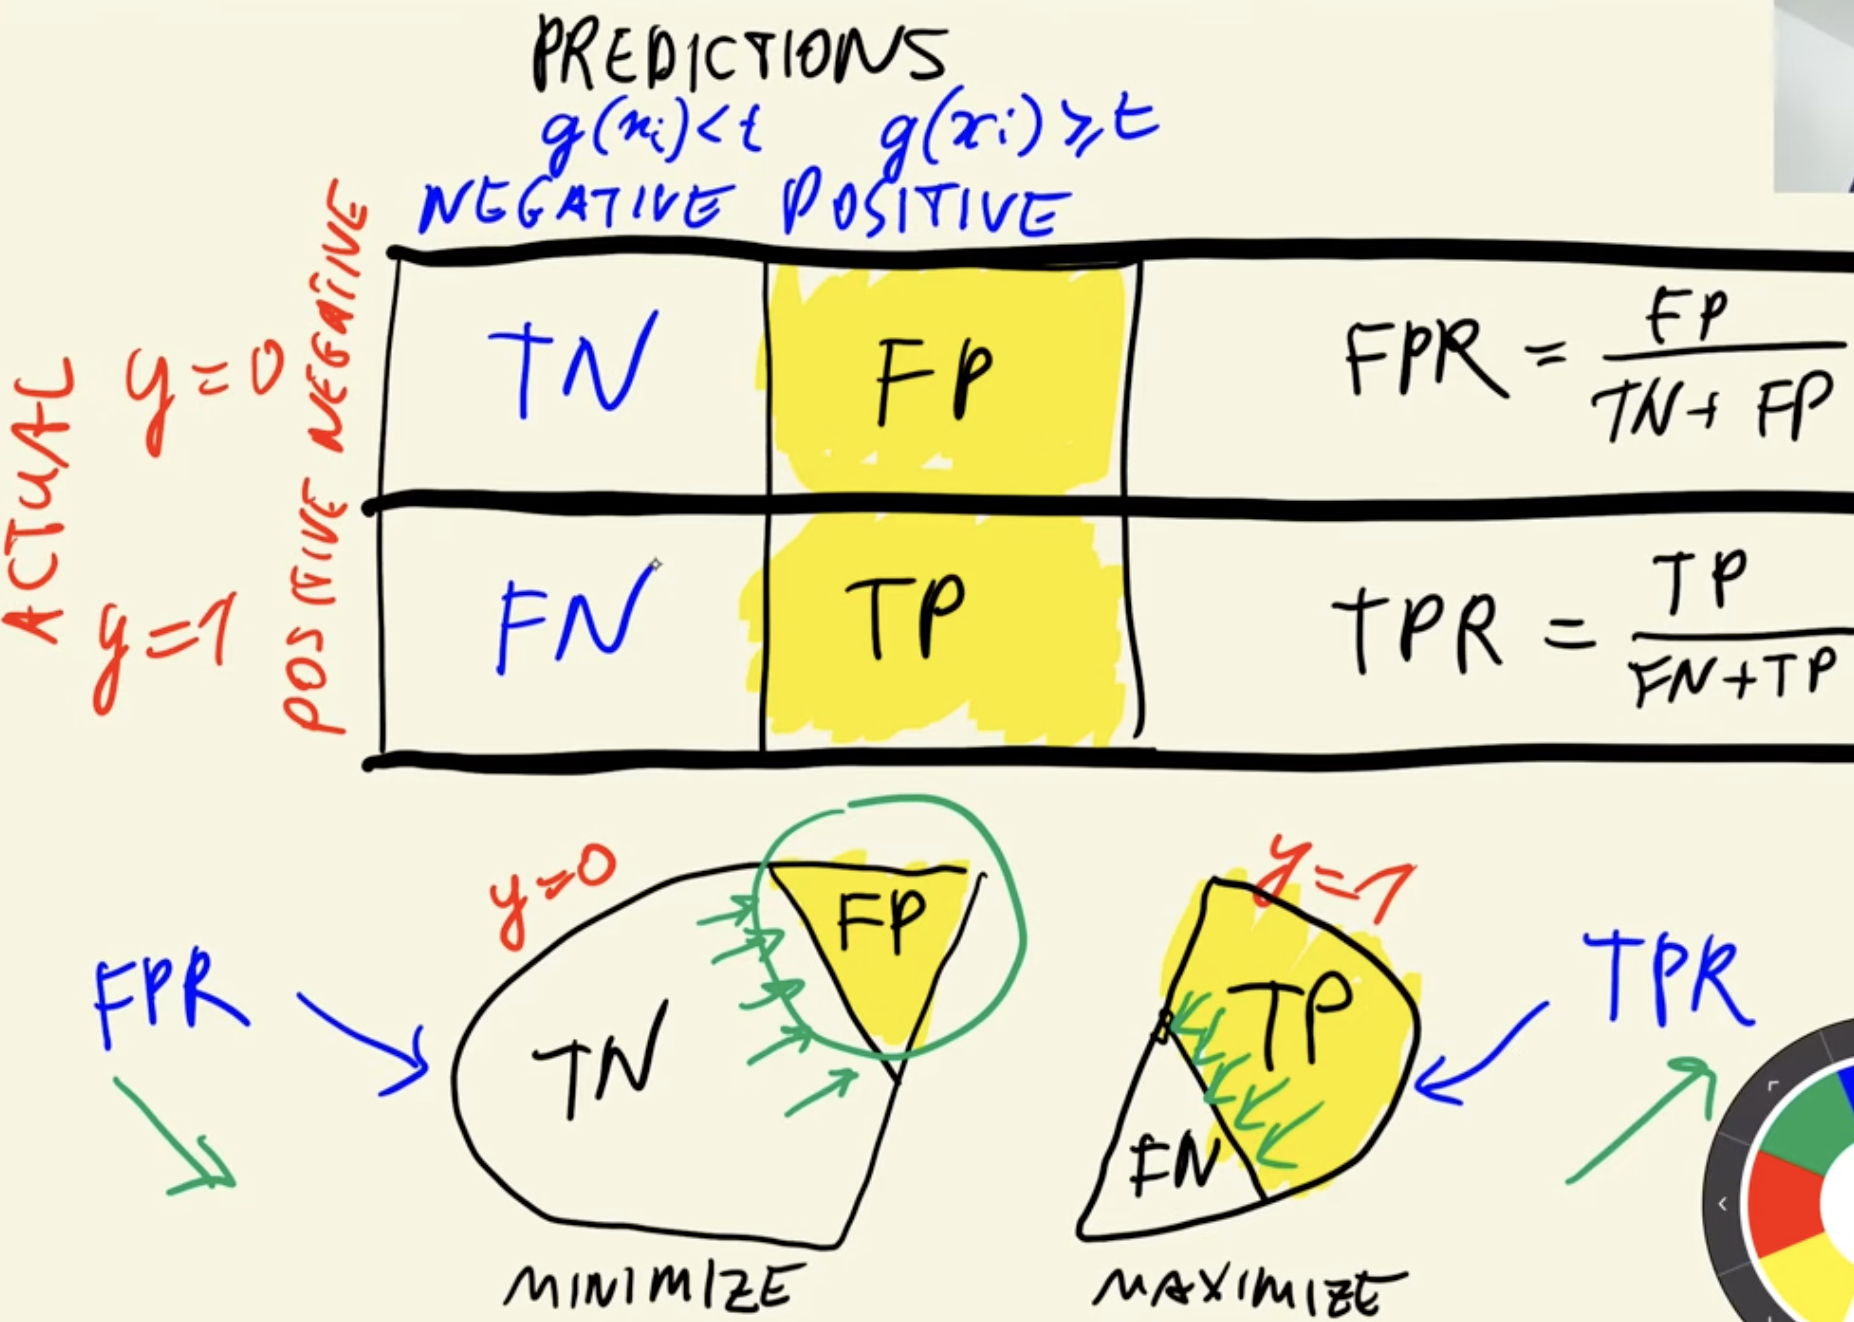{width=200px}

In [34]:
tpr = tp / (tp+fn)
tpr

np.float64(0.5492227979274611)

In [35]:
fpr = fp / (fp+tn)
fpr

np.float64(0.09970674486803519)

In [36]:
scores = []
thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred_proba >= t)
    predict_negative = (y_pred_proba < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

In [37]:
columns = ['threshiold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

In [38]:
df_scores

,threshiold,tp,fp,fn,tn
0,0.00,386,1023,0,0
1,0.01,385,898,1,125
2,0.02,383,806,3,217
3,0.03,382,751,4,272
4,0.04,382,712,4,311
...,...,...,...,...,...
96,0.96,0,0,386,1023
97,0.97,0,0,386,1023
98,0.98,0,0,386,1023
99,0.99,0,0,386,1023


In [39]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [40]:
df_scores[::10]

,threshiold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,367,537,19,486,0.950777,0.524927
20,0.2,339,371,47,652,0.878238,0.362659
30,0.3,292,248,94,775,0.756477,0.242424
40,0.4,253,176,133,847,0.655440,0.172043
50,0.5,212,102,174,921,0.549223,0.099707
60,0.6,152,52,234,971,0.393782,0.050831
70,0.7,69,14,317,1009,0.178756,0.013685
80,0.8,5,0,381,1023,0.012953,0.000000
90,0.9,0,0,386,1023,0.000000,0.000000


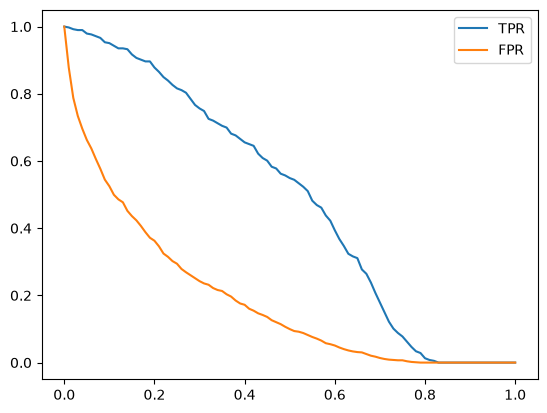

In [41]:
plt.plot(df_scores.threshiold, df_scores['tpr'], label="TPR")
plt.plot(df_scores.threshiold, df_scores['fpr'], label="FPR")
plt.legend()

### Random Model